In [1]:
%load_ext autoreload
%autoreload 2
%aimport -fiftyone

from detection_common import configure_stdio_relative_path

from dataset_builder.config import WORKSPACE_ROOT

# Display project paths relatively for consistent output across environments.
configure_stdio_relative_path(WORKSPACE_ROOT)

In [2]:
from collections import defaultdict
from typing import cast

import fiftyone as fo

MASTER_DATASET = "sports_objects_master"

# Dataset Deduplication

1. **Exact-duplicate detection**. Select one representative per exact group for
subsequent analysis.
2. **Compute and cache a separate perceptual_hash field**. Compare hashes using
Hamming distance, then display candidate pairs or groups for review.
3. **Run embedding-based detection on those same exact-group representatives**. Keep
   unconfirmed perceptual matches in this search; they may help reveal additional
   relationships.
4. **Record each method separately**, for example with `review:perceptual_duplicate`
and `review:embedding_duplicate` tags. Show references alongside candidates and retain
all samples during review.

Tag exact pixel duplicates using the `pixel_digest` field cached during import.
This does not detect pixel changes introduced by lossy recompression.

## 1. Load the master sport object detection dataset

The "sports_objects_master" should have been created by `nb01.07.01`.

In [3]:
import logging

logging.getLogger("fiftyone.core.config").setLevel(logging.ERROR)

if not fo.dataset_exists(MASTER_DATASET):
    raise ValueError(f"Dataset {MASTER_DATASET!r} not found. Run nb01.07.01 first.")

master = fo.load_dataset(MASTER_DATASET)
master.persistent = True
if not master.has_sample_field("pixel_digest"):
    raise ValueError("Run nb01.07.01 to populate the pixel_digest field first.")

## 2. Detecting exact duplicates (image pixel hash)

### 2.1 Tag exact pixel duplicates for review

Group the stored digests without reopening images. Keep the first sample in
each group untagged and tag the remaining copies. Refresh this review tag on
reruns. This includes byte-identical files and other encodings with identical
normalized pixels. Samples and media files are retained for review.

In [4]:
# FiftyOne's inferred aggregation type does not describe this two-field result.
sample_ids, pixel_digests = cast(
    tuple[list[str], list[str | None]],
    master.values(["id", "pixel_digest"]),
)
if any(not digest for digest in pixel_digests):
    raise ValueError("Every sample must have a pixel_digest before tagging.")

ids_by_digest = defaultdict(list)
for sample_id, digest in zip(sample_ids, pixel_digests):
    ids_by_digest[digest].append(sample_id)

duplicate_ids = [sid for ids in ids_by_digest.values() for sid in ids[1:]]
master.untag_samples("review:exact_duplicate")
if duplicate_ids:
    master.select(duplicate_ids).tag_samples("review:exact_duplicate")

dup_groups_cnt = sum(len(ids) > 1 for ids in ids_by_digest.values())
print("Exact pixel duplicate groups:", dup_groups_cnt)
print("Tagged extra copies:", len(duplicate_ids))

Exact pixel duplicate groups: 295
Tagged extra copies: 389


### 2.2 Run FiftyOne Apps for visual reviews of exact duplicates.

#### 2.2.1 Show all duplicate samples

Show all duplicate groups, including their untagged first samples. Rebuild the
selection from the digest groups so earlier reviews cannot consume it. Sort by
digest to keep matching samples adjacent in the App.


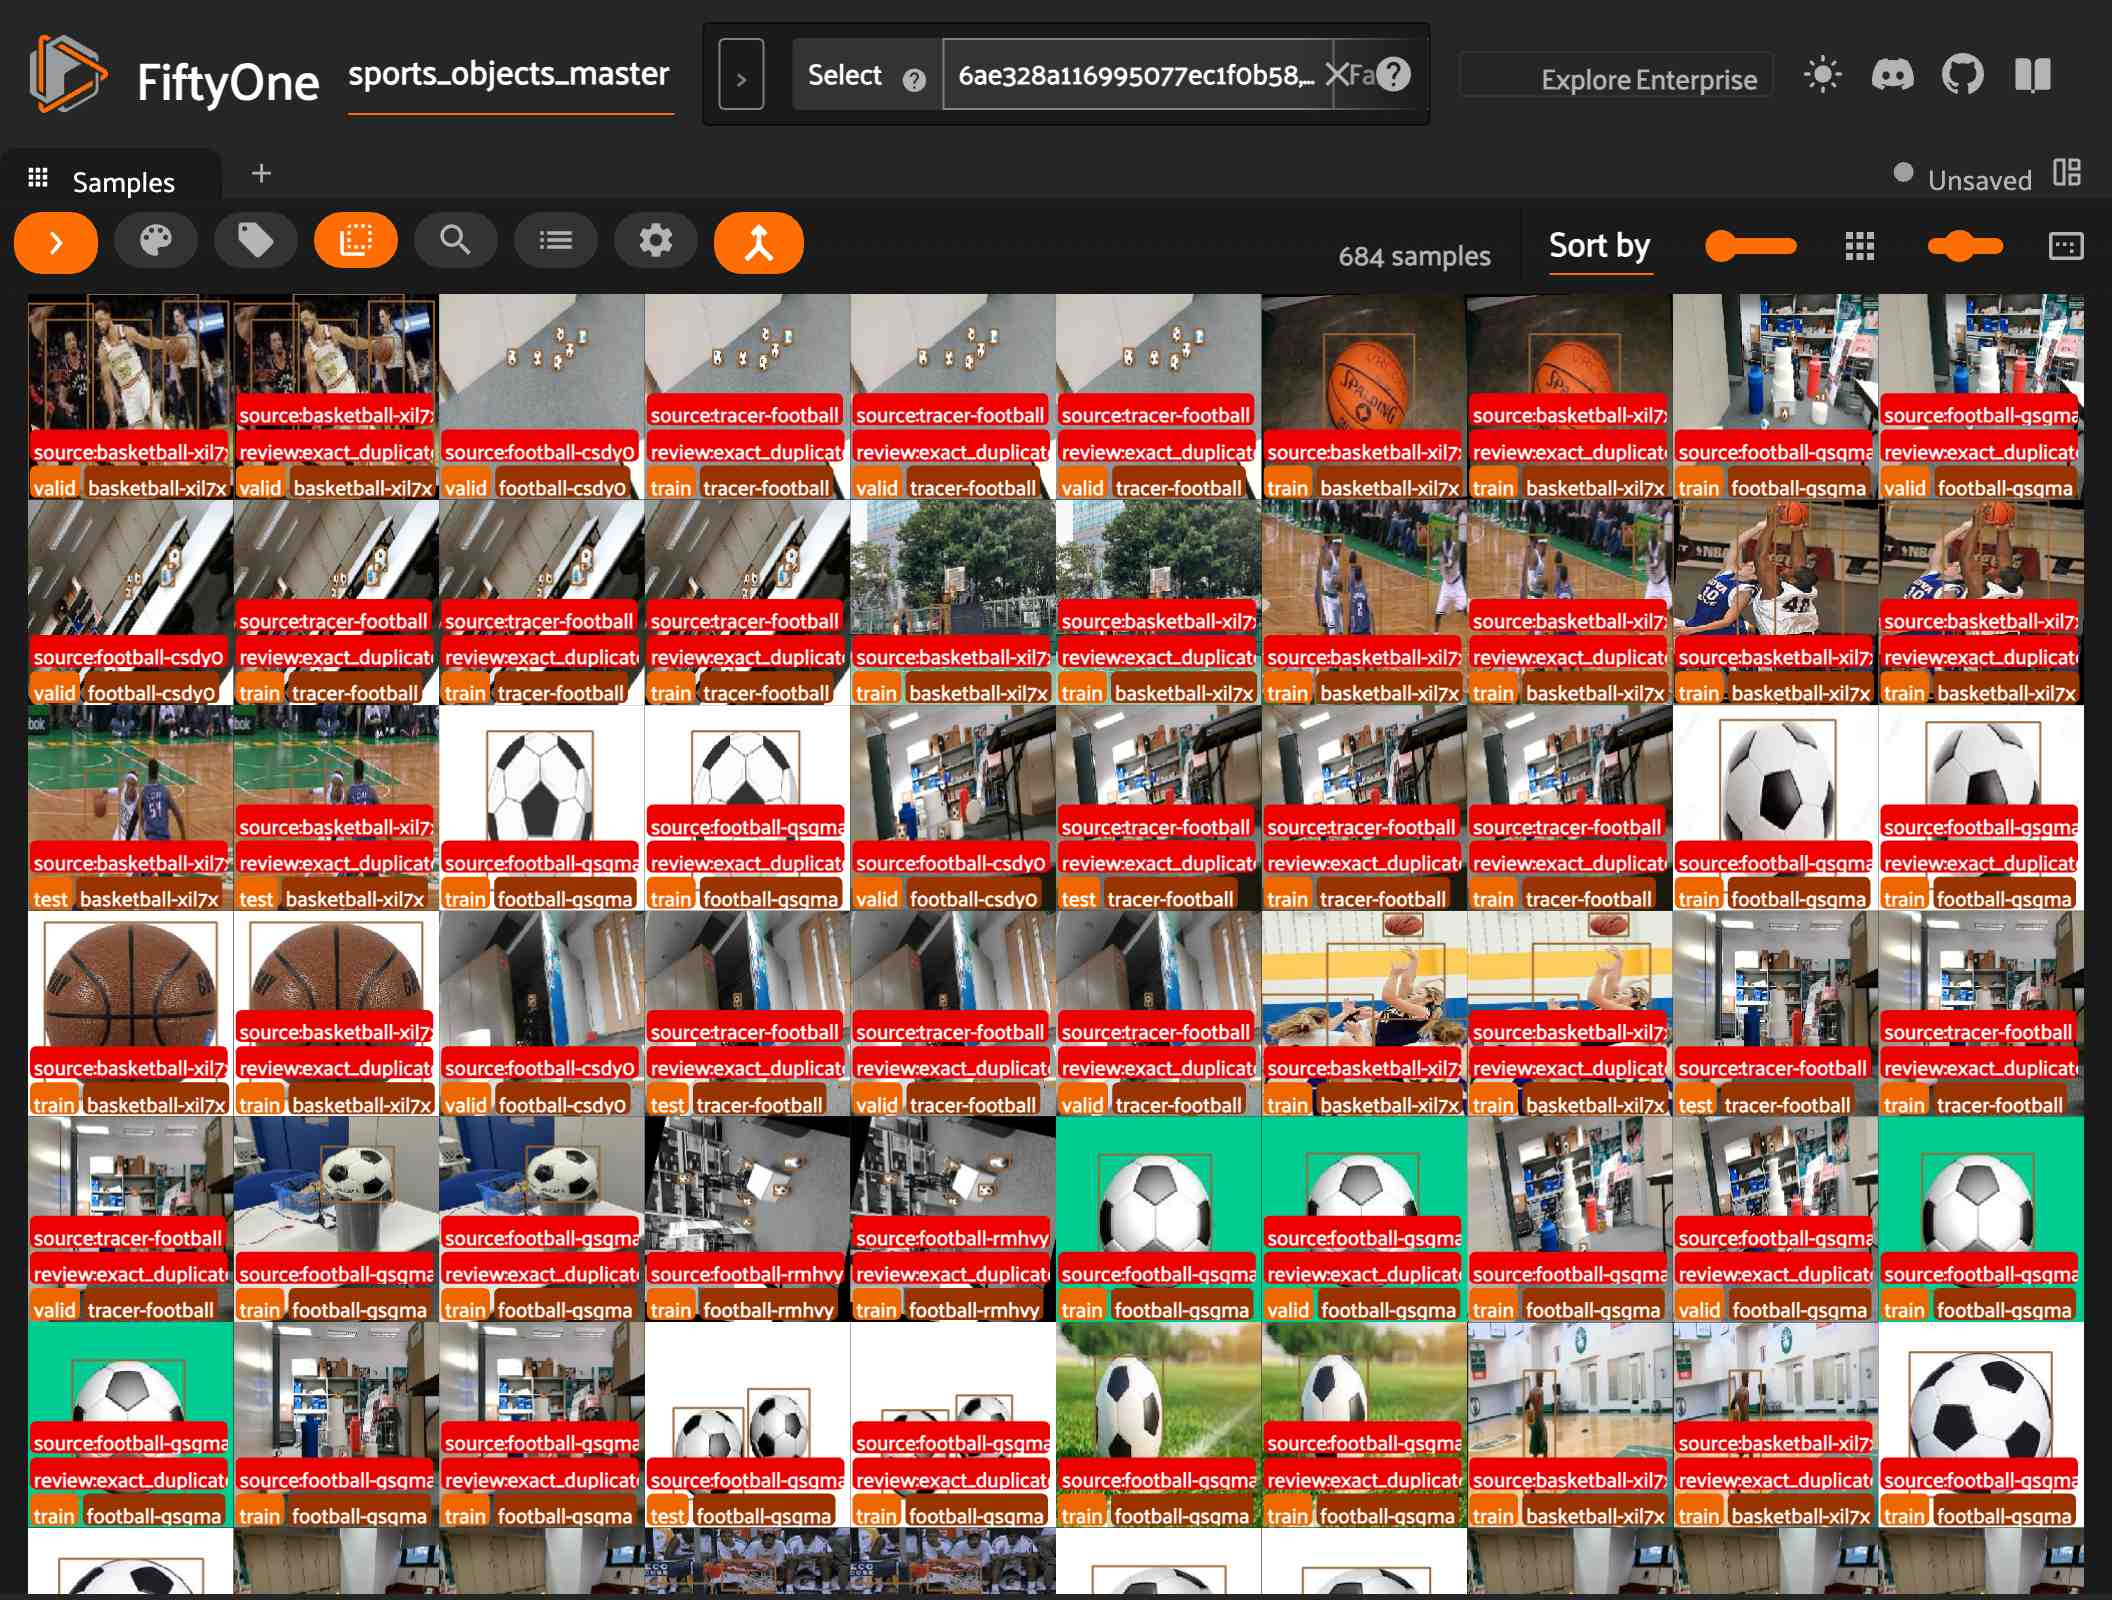

In [5]:
all_duplicate_ids = [
    sid for ids in ids_by_digest.values() if len(ids) > 1 for sid in ids
]
review_view = master.select(all_duplicate_ids).sort_by("pixel_digest")
session = fo.launch_app(view=review_view)

#### 2.2.2 Iteratively review

In [ ]:
session.freeze()
duplicate_samples = (ids for ids in ids_by_digest.values() if len(ids) > 1)

Iteratively run the following cell to do visual review on the duplicated samples:


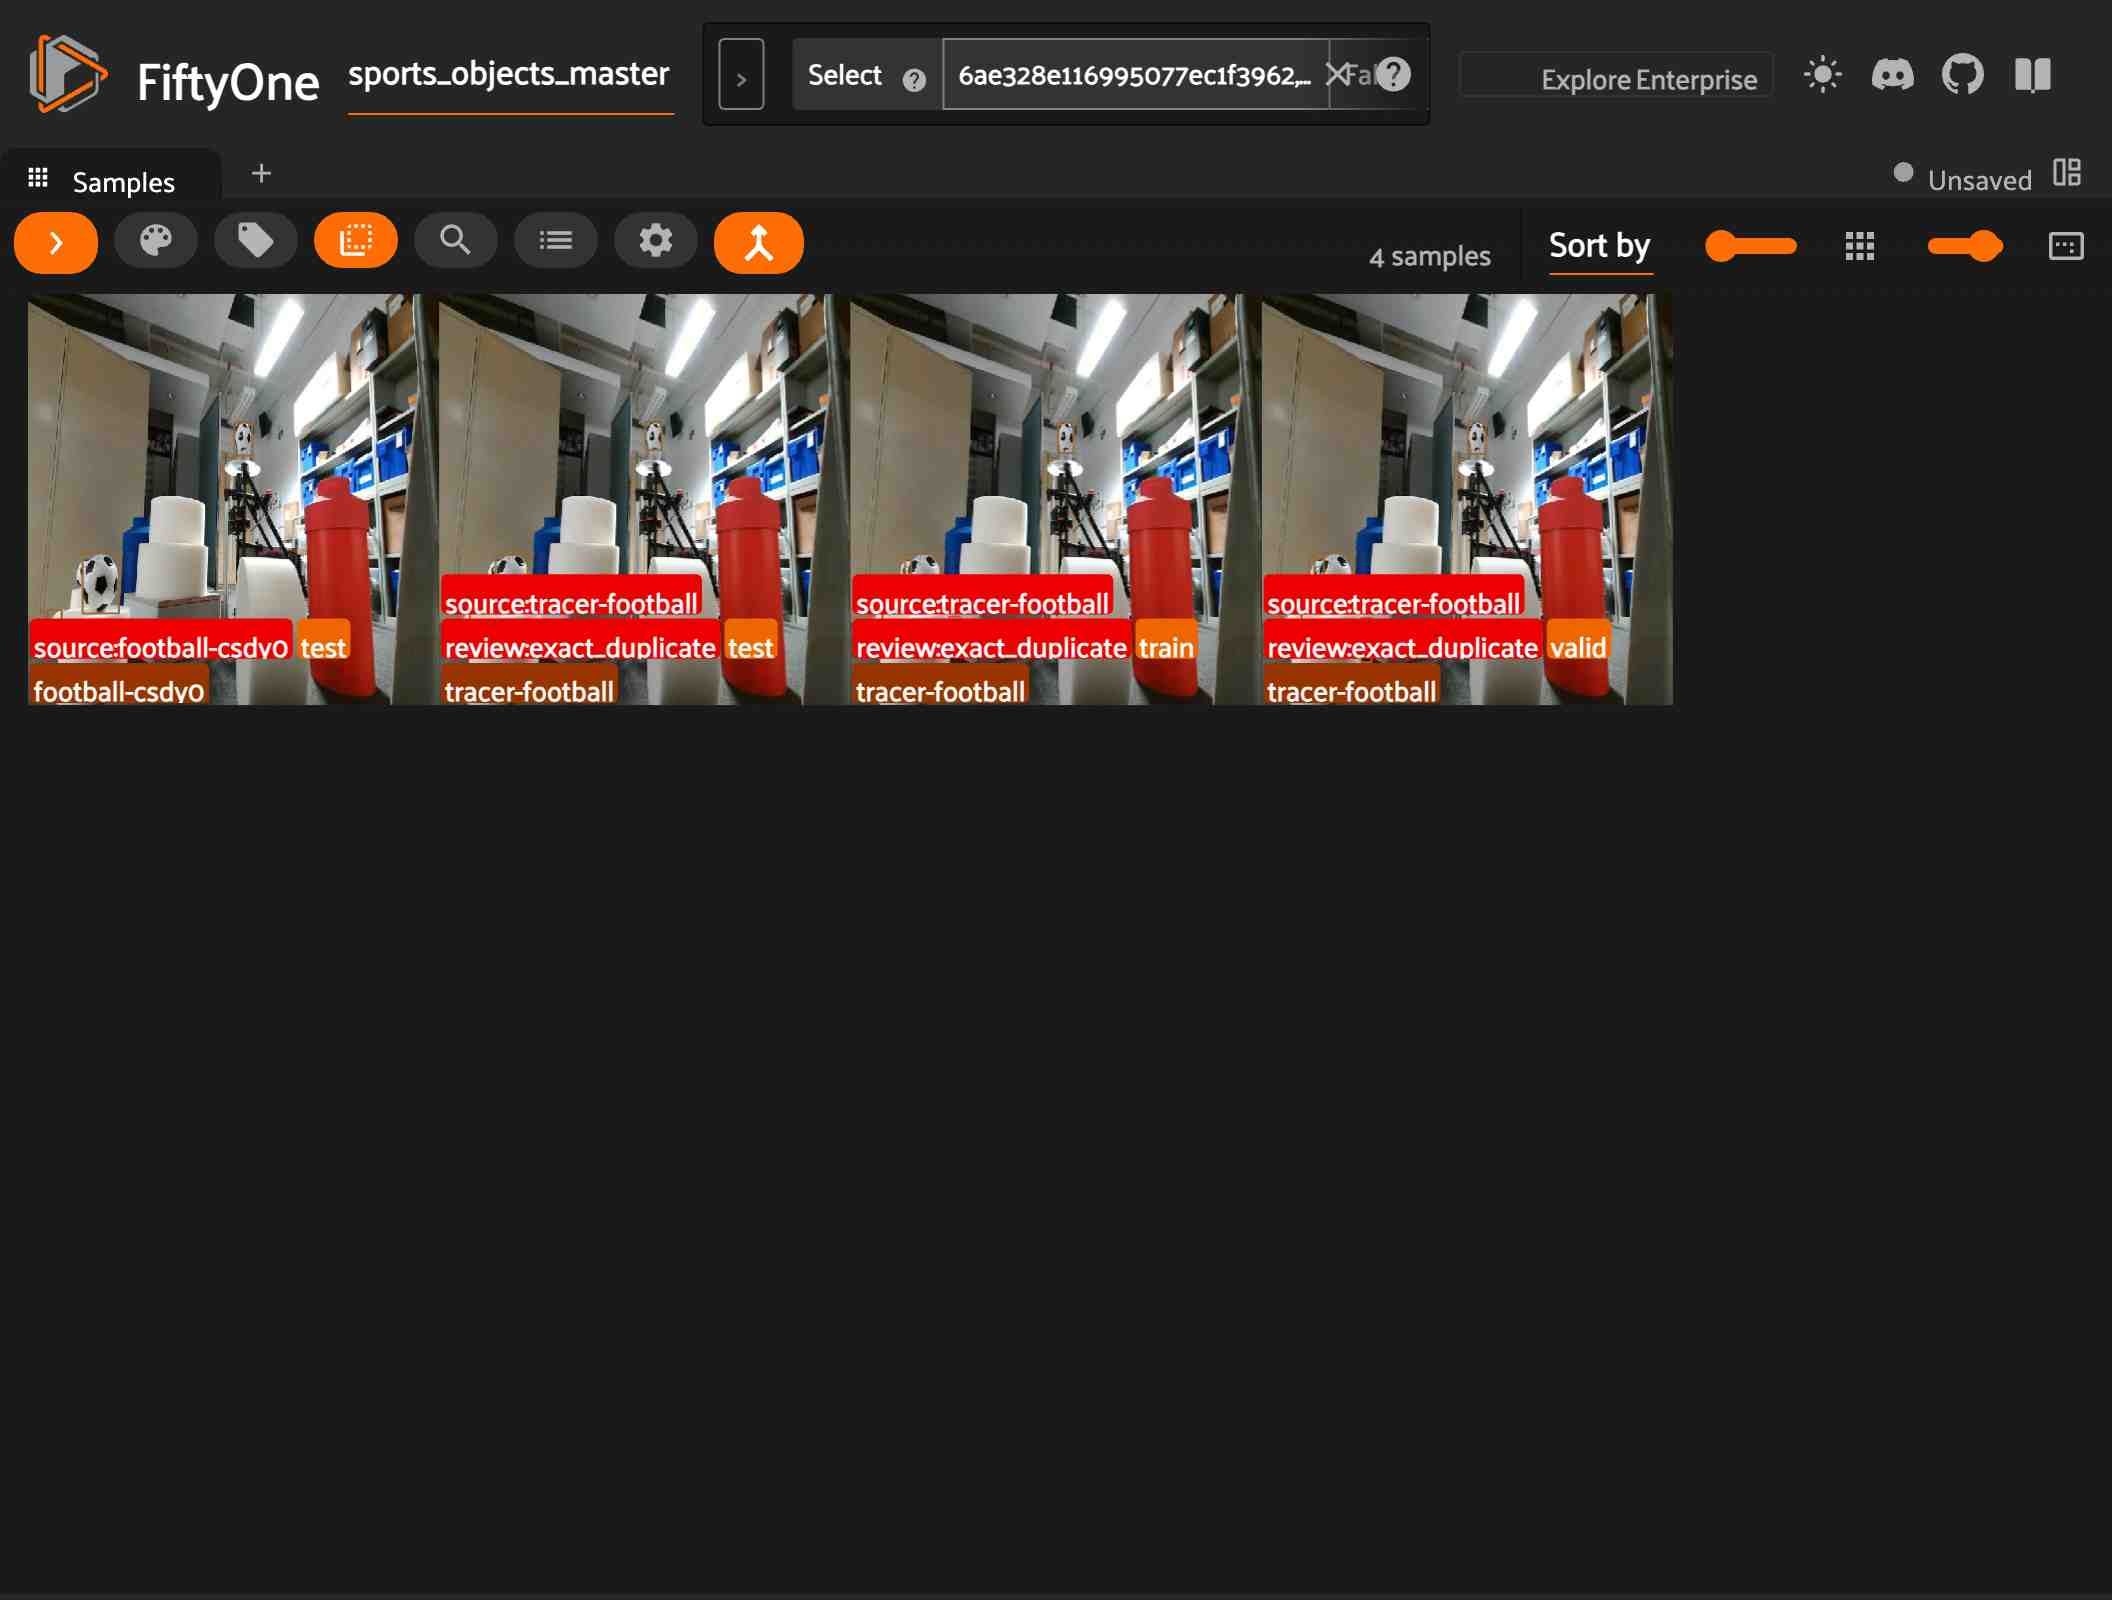

In [115]:
group_ids = next(duplicate_samples, None)
if group_ids:
    review_view = master.select(group_ids)
    session = fo.launch_app(view=review_view)

In [ ]:
session.freeze()

## 3. Detecting perceptually duplicates (perceptual hash)

### 3.1 Set up pHash

Use `imagehash.phash(image, hash_size=PHASH_SIZE)` for 64-bit fingerprints.
ImageHash hashes and compares images on CPU without a model download.

In [ ]:
import imagehash

PHASH_SIZE = 8

## 4. Detecting near duplicates (embedding similarity)